# [1] 10 Rainfall at Tule Pond and the onset seasonality

```
Created on Thu Sep 24 2026
@author: daniellelindsay
Run in opera_disp_feb13. Seconds.
```

**What this notebook does.**

1. **Daily rain at Tule Pond** from the two nearest NOAA GHCN-daily gauges,
   spliced day by day, Fremont first, then Newark (no rescaling; the overlap is
   documented). Hayward Air Terminal (18 km) is read only as the midnight-basis
   reference for the check below; it is not in the composite (Dani 2026-10-02:
   it filled only 69 days, so two gauges is the cleaner record). The morning-observer COOP gauge
   (Newark) is shifted one day earlier onto the midnight basis, and that shift
   is checked against Hayward and on a storm with a date in the news. Over the InSAR events
   the record is Fremont alone (asserted), so the storm analysis, which uses only the InSAR
   events, sees one consistent gauge; the Newark fill serves the other years, for display. Water year Oct 1 to Sep 30,
   named by the year it ends. The gauge files in `external_inputs/GHCN_daily`
   (`common_paths["ghcn_dir"]`) are the frozen inputs: a missing one stops the notebook
   (`TULEPOND_DOWNLOAD_GHCN=1` downloads it instead).
2. **The event table**: the InSAR and HRKT (bimonthly-era) events with their
   window, step and the rain around the window (`event_table.csv`).
3. **Onset seasonality**: every season-resolved onset (the InSAR windows and the
   bimonthly-era array windows, all `aa_dense_window_days` (130 d) or less) on the water year over the rain
   (a working figure here; the paper's Fig 3B is drawn by 11_forecast from the
   panel products this notebook saves). The wet season is October to April
   (`wet_season_months`, Dani 2026-10-05), the same months as 11_forecast's
   "WY2027 wet season" (one definition, `TulePond_filepaths.wet_season_months`).
4. **Rainfall conditioning of the onsets** (moved here from 11_forecast on 2026-10-06; the
   tests and their numbers are unchanged): for each onset window the water-year rain
   accumulated by then, the lag after fixed cumulative thresholds (rule A) and after the first
   storm of the year (rule B); then the test of a 3-day rain total before the onset: does an
   InSAR onset fall within X days after a 3-day rain total of at least Z mm more often than a
   random day of the same season in the same water year? Only the five InSAR onsets and only
   the Fremont gauge; Z and X are swept (16 settings) and the search is paid for. The scalars
   11's prediction statement quotes are written to `rain_conditioning_summary.csv`.

**The day convention (the one place it is defined; 11_forecast and drafts/10x read
the days this notebook writes).** InSAR acquisitions are UTC: the ascending pass
(09157) is at ~02:08Z, the evening of the PREVIOUS local day (18:08 PST), the descending
pass (11115) at ~14:08Z, the morning of the same local day (06:08 PST); the times are
read from the OPERA granule names. Rain is booked by the LOCAL day (Fremont midnight
basis; Newark, a morning observer, shifted -1 d onto it, Fremont 0 d, both asserted).
So every InSAR onset window is turned into local calendar days before it meets the
rain: the first day is the local day of the LATER acquisition among the tracks that
acquired on `onset_lo`, the last day is the local day of the EARLIER acquisition among
the tracks that acquired on `onset_hi` (the tracks that acquired on a date are the
columns of 03's per-track series). The window is inclusive of both days. The local
day is computed in `rain_day_timezone` and must equal the standard-time (UTC-8) day
(asserted: no acquisition is near local midnight, so daylight saving cannot move it).
Array windows are survey days, already local. The renewal forecast of 11 works in
continuous decimal years and is not affected (hours).

The forecast of the next event is notebook 11 (11_forecast), which reads this notebook's Fig 3 panel
products and `rain_conditioning_summary.csv` (part (3) of its prediction statement).

PREPUB: Ported from `Hayward_DISP-S1/analysis/run20_precip_ghcn.py` and
PREPUB: `plotting/fig_hrkt_onset_seasonality.py`.

**Inputs**: the three GHCN-daily gauge files (two in the composite, Hayward the check gauge), 04 `creep_events.csv` (InSAR onset windows, `onset_lo`
to `onset_hi`), 09 `hrkt_aa_events.csv` (array onset windows, the same columns, plus `onset_mid`, the
window midpoint, for plot positions only) and `aa_insar_stacks.csv` (the start of the InSAR
record), the HRKT array file (the end of its bimonthly surveys), 03 `creep_ts_LOS_<track>.csv`
(the header only: each track's acquisition dates) and the OPERA granule names of each frame
(`TulePond_filepaths.frames[<frame>]["data_dir"]`; the names only: each acquisition's UTC time).

**Outputs** (`outputs/10_rain_seasonality/`): `tulepond_daily_precip.csv`,
`wateryear_totals.csv`, `event_table.csv` (window ends as local days, `window_day_basis`),
the Fig 3 panel products `fig3_rain_panel.npz` (with the wet-season months) and
`fig3_onset_windows.csv` (one row per onset window of both catalogues: `onset_lo`, `onset_hi`,
`onset_mid` for the plot position, the window as local calendar days `day_lo`, `day_hi`, the UTC
acquisitions that bound an InSAR window `utc_lo`, `utc_hi`, and the day of water year of each
end; read by 11), the rainfall conditioning `precip_conditioning_{events,thresholds}.csv`, `rain_total_sweep.csv`
(the 16 settings of the 3-day rain-total test: hits, null expectation, p) and `rain_conditioning_summary.csv`
(one row per scalar 11's prediction statement quotes: name, value, unit), the stats sidecar `10_rain_stats.txt`,
registry rows `10_*`.

**Figures**: `qc10_onset_seasonality_wateryear_density7d_vmax80mm` (working figure, not Fig 3); the cumulative
rain of every water year (`figS_wy_cumulative_rain_onsets`) and the rainfall conditioning with the p of every
setting of the rain-total test (`figS_precip_conditioning_bestY<Y>mm_rain3d_sweep16_nnull<n>`), supplement.

**What to check.** Fremont reads ~12 % more than Newark in the median water year (ratio
0.73-1.29 over the complete years; no rescaling); Newark shifted by one day agrees better with
Hayward on storm days and lines up with it on the 11 Dec 2014 storm (both asserted); every InSAR
onset window and the 30 days before it on Fremont alone (asserted: the Newark fill does not
enter the InSAR analysis); the InSAR windows in local days (printed beside the UTC days: a window
whose first or last acquisition is ascending starts or ends one day earlier); the onset windows
counted against the wet season BY WINDOW, not midpoint (October to April: wholly inside, partly,
wholly outside; `10_n_wet_<season>_*`, e.g. `10_n_wet_oct_apr_inside`); the InSAR onset windows fall in
December to March (`10_insar_onset_earliest`, `_latest`); the rain-total test: the search-paid p
(`10_rain_sweep_p_search_paid`) is the number to quote, not the best setting's own p (`10_rain_sweep_best_p`).

PREPUB: The rainfall-conditioning keys were 11_forecast's until 2026-10-06 (`11_onset_*`, `11_wy_*`,
PREPUB: `11_cum_at_*`, `11_frac_at_*`, `11_ruleA_*`, `11_ruleB_*`, `11_rain_sweep_*`); 11 no longer registers them,
PREPUB: so registry.txt lists them as RETIRED; their values are now `10_insar_onset_*`, `10_insar_wy_*`,
PREPUB: `10_insar_cum_at_onset_*`, `10_insar_frac_at_onset_*`, `10_ruleA_*`, `10_ruleB_*`, `10_rain_sweep_*`.

PREPUB: Until 2026-10-05 the count used November to March under the keys `10_n_wet_season_inside`,
PREPUB: `_partly`, `_outside`, `10_n_insar_wet_season_inside` and `10_wet_season_rain_pct`. Those keys are
PREPUB: no longer registered, so registry.txt lists them as RETIRED; do not quote them.

In [1]:
# [2]
import calendar
import glob
import os
import re
import urllib.request

import insar_utils as utils
from TulePond_filepaths import common_paths, paths_out, repo_dir, forecast_issue_date, rain_total_days, rain_total_mm
from TulePond_filepaths import wet_season_months as wet_season_first_last, aa_dense_window_days, loma_prieta_yr
from TulePond_filepaths import frames, insar_dic_list

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

## [3] Paths and parameters

The gauges, the wet season, the figure settings and the input files; the registry records the inputs.

In [2]:
# [4]
notebook = "10_rain_seasonality"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)


# the gauges: id -> (short name, order in the composite, day shift for morning-observer COOP gauges).
# The composite is the two nearest Tule Pond (4 and 7 km); Hayward Air Terminal (18 km) is the midnight-basis
# reference for the Newark observation-time check only.
# PREPUB: Livermore, San Jose and Oakland Museum (22 to 37 km) were carried as alternates until 2026-09-24 and entered no number.
ncei = "https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/{sid}.csv"
download_missing = os.environ.get("TULEPOND_DOWNLOAD_GHCN", "0") == "1"   # 1: download a missing gauge file (the files are frozen inputs)
stations = {"USC00043244": ("FREMONT", "composite-1", 0),      # COOP but on the midnight basis (checked against Hayward)
            "USC00046144": ("NEWARK", "composite-2", -1),      # COOP, morning observer (checked on the 11 Dec 2014 storm below)
            "USW00093228": ("HAYWARD_AT", "check only", 0)}    # ASOS, midnight basis: the reference for the Newark shift check
composite = ["FREMONT", "NEWARK"]
tulepond = (37.557, -121.970)      # section centre (lat, lon)
t_start = "1978-10-01"             # start of WY1979 (first HRKT survey 1979.7)
series_end = pd.Timestamp(forecast_issue_date)   # the rain series ends at the forecast issue date so the run reproduces
max_missing_days = 20              # a water year with at most this many missing days is "complete"
min_gauge_days = 350               # gauge comparison: water years in which both gauges reported on at least this many days
storm_day_mm = 10.0                # gauge comparison: days on which either gauge has at least this much rain
complete_wy = (1980, 2025)         # the complete water years the rain climatology is quoted over
insar_rain_check_days = 30         # the one-gauge check: each InSAR window and this many days before it must be Fremont alone

# the day convention (header): InSAR acquisitions are UTC, rain is booked by the local day
rain_day_timezone = "America/Los_Angeles"   # the gauges' local day
rain_day_standard_offset_h = -8             # local standard time (PST); the local day must come out the same (asserted)

# the seasonality
resolvable_days = aa_dense_window_days   # array windows longer than this do not constrain the season (TulePond_filepaths: 09's bimonthly era)
# the wet season, (first month, last month): ONE definition for this onset count and 11's forecast window (Dani
# 2026-10-05: October to April), TulePond_filepaths.wet_season_months (imported above: a missing value stops the
# import; 11 checks it against the months saved here)
wet_season_source = "TulePond_filepaths.wet_season_months"
assert len(wet_season_first_last) == 2 and all(int(m) == m and 1 <= m <= 12 for m in wet_season_first_last), \
    f"wet_season_months must be (first month, last month), got {wet_season_first_last}"
first_wet_month, last_wet_month = (int(m) for m in wet_season_first_last)
wet_season_months = []                     # the months of the season in order, wrapping across the new year
for k in range((last_wet_month - first_wet_month) % 12 + 1):
    wet_season_months.append((first_wet_month - 1 + k) % 12 + 1)
wet_season_tag = f"{calendar.month_abbr[first_wet_month].lower()}_{calendar.month_abbr[last_wet_month].lower()}"   # in the registry keys
wet_season_text = f"{calendar.month_name[first_wet_month]} to {calendar.month_name[last_wet_month]}"
print(f"wet season {wet_season_text}, months {wet_season_months} ({wet_season_source})")
density_days = 7           # the figure: running rain total (days)
density_max = 80           # ... mm at full colour
rain_colours = ["#FFFFFF", "#C6DBEF", "#4292C6", "#08306B"]      # sequential blues for the rain (no other blue on the panel)
insar_bar_colour = "#D55E00"      # Okabe-Ito vermillion
array_bar_colour = "0.15"         # near black
x0, x1 = 1979.0, 2026.5           # the time axis of Fig 3: the HRKT record starts 1979.7
loma_prieta = loma_prieta_yr      # 17 Oct 1989 (TulePond_filepaths), saved for Fig 3A

# the rainfall conditioning ([17]-[24], moved from 11_forecast 2026-10-06; same grids and seed as there)
y_grid = [50, 75, 100, 125, 150, 175, 200, 250, 300, 400]   # WY cumulative thresholds, mm (rule A)
z_grid = [15, 20, 25, 30, 40, 50, 75]                       # first-storm sizes (3-day totals), mm (rule B)
rain_total_grid_mm = [20, 30, 40, 50]                       # the rain-total test: 3-day rain total of at least Z mm ...
rain_lag_grid_d = [7, 14, 21, 30]                           # ... within X days before the InSAR onset
antecedent_storm_mm = 20     # the "days since a storm" columns of precip_conditioning_events.csv use this SMALLER storm
#                              (a 3-day total >= 20 mm), not rain_total_mm (40 mm, the event table's description)
n_draws = 2000               # rain-total test: onset draws per InSAR event, uniform over the days of its window
n_null = 20000               # rain-total test: null realisations (each event in its own water year, on a day of the onset season)
rain_test_seed = 7           # the rain-total test's own random-number generator (the seed it had in 11)

# the InSAR stacks at the six arrays (09); only HRKT's first date is used here (the start of the InSAR record for Fig 3A)
stacks_file = os.path.join(paths_out["09_alignment_arrays"], "aa_insar_stacks.csv")
hrkt_file = os.path.join(common_paths["aa_dir"], "HRKT.csv")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
aa_events_file = os.path.join(paths_out["09_alignment_arrays"], "hrkt_aa_events.csv")
# each track's acquisition dates (03's per-track series, header only) and the frame whose granule names give their UTC times
track_files = {}
granule_dirs = {}
for dic in insar_dic_list:
    track_files[dic["ORBIT_DIRECTION"]] = os.path.join(paths_out["03_creep_timeseries"], f"creep_ts_LOS_{dic['ORBIT_DIRECTION']}.csv")
    granule_dirs[dic["ORBIT_DIRECTION"]] = (dic["Frame"], frames[dic["Frame"]]["data_dir"])

REG = utils.Registry(notebook, common_paths, repo_dir)
gauge_files = []
for sid in stations:
    gauge_files.append(os.path.join(common_paths["ghcn_dir"], f"{sid}.csv"))
REG.inputs(events_file, aa_events_file, stacks_file, hrkt_file, *gauge_files, *track_files.values())

wet season October to April, months [10, 11, 12, 1, 2, 3, 4] (TulePond_filepaths.wet_season_months)
Registry for 10_rain_seasonality: run 6e710468, git 6168603+


## [5] Functions: dates, water years and the local day of an acquisition

Water year N runs Oct 1 of N-1 to Sep 30 of N; day of water year counts
from Oct 1 = 1. A decimal year is turned into its calendar day first, so
every day of water year in this notebook comes from the same calendar.
An InSAR acquisition's UTC time comes from its OPERA granule name, and its
rain day is the local day of that time (the day convention, header).

In [3]:
# [6]
def decyear(dates):
    """Decimal year of a DatetimeIndex, fraction of the actual year length."""
    dates = pd.DatetimeIndex(dates)
    year_start = pd.to_datetime(dates.year.astype(str) + "-01-01")
    next_year_start = pd.to_datetime((dates.year + 1).astype(str) + "-01-01")
    return dates.year + (dates - year_start) / (next_year_start - year_start)


def to_date(decimal_years):
    """The calendar day nearest to each decimal year (an acquisition's own day, not the day before)."""
    out = []
    for value in np.atleast_1d(decimal_years):
        out.append(utils.decimal_year_to_day(value))
    return pd.DatetimeIndex(out)


def water_year(dates):
    """Water year of each date: Oct 1 of N-1 to Sep 30 of N is water year N."""
    dates = pd.DatetimeIndex(dates)
    return dates.year + (dates.month >= 10).astype(int)


def dowy(dates):
    """Day of water year: Oct 1 = 1."""
    dates = pd.DatetimeIndex(dates)
    wy_start = pd.to_datetime((water_year(dates) - 1).astype(str) + "-10-01")
    return (dates - wy_start).days + 1


def dowy_frac(decimal_years):
    """Day of water year (Oct 1 = 1) of decimal years, through their calendar day."""
    return np.asarray(dowy(to_date(decimal_years)))


def dowy_of(date):
    """(day of water year, water year) of one Timestamp; Oct 1 = 1."""
    return int(dowy([date])[0]), int(water_year([date])[0])


def dowy_label(day):
    """A day of water year as 'Mon DD' ('--' if undefined)."""
    if not np.isfinite(day):
        return "--"
    return (pd.Timestamp("2000-10-01") + pd.Timedelta(days=int(day) - 1)).strftime("%b %d")


def sigma_from_ci95(lo, hi):
    """1 sigma from a 95 % interval: for a normal distribution it spans mean +/- 1.96 sigma (full width 3.92 sigma)."""
    return (hi - lo) / 3.92


def acquisition_clock(frame, granule_dir):
    """The UTC time of every secondary acquisition of one OPERA DISP-S1 frame, from the granule names
    (OPERA_L3_DISP-S1_IW_F<frame>_VV_<reference>Z_<secondary>Z_v...nc), as a Series indexed by the UTC day."""
    names = sorted(glob.glob(os.path.join(granule_dir, f"OPERA_L3_DISP-S1_IW_F{frame}_VV_*.nc")))
    assert names, f"no OPERA granules of frame {frame} in {granule_dir}"
    times = []
    for name in names:
        match = re.search(r"_(\d{8}T\d{6})Z_(\d{8}T\d{6})Z_v", os.path.basename(name))
        assert match, f"unexpected granule name {os.path.basename(name)}"
        times.append(pd.Timestamp(match.group(2)))
    clock = pd.Series(times, index=pd.DatetimeIndex(times).normalize()).sort_index()
    assert clock.index.is_unique, f"frame {frame}: two granules share a secondary day"
    return clock


def local_day(utc_time):
    """The local calendar day (the rain day) of a UTC time; it must be the same in standard time (asserted)."""
    local = pd.Timestamp(utc_time).tz_localize("UTC").tz_convert(rain_day_timezone).tz_localize(None).normalize()
    standard = (pd.Timestamp(utc_time) + pd.Timedelta(hours=rain_day_standard_offset_h)).normalize()
    assert local == standard, f"{utc_time} UTC is near local midnight: its rain day depends on daylight saving"
    return local


def insar_local_window(onset_lo, onset_hi):
    """An InSAR onset window as local calendar days (inclusive): from the local day of the LATER acquisition among the
    tracks that acquired on the UTC day of onset_lo, to the local day of the EARLIER acquisition among the tracks
    that acquired on the UTC day of onset_hi. Returns (first day, last day, the bounding UTC times, their tracks)."""
    utc_day_lo = utils.decimal_year_to_day(onset_lo)
    utc_day_hi = utils.decimal_year_to_day(onset_hi)
    before = {}
    after = {}
    for track in track_days:
        if utc_day_lo in track_days[track]:
            before[track] = track_clock[track][utc_day_lo]
        if utc_day_hi in track_days[track]:
            after[track] = track_clock[track][utc_day_hi]
    assert before and after, f"window {utc_day_lo.date()}..{utc_day_hi.date()}: an end is not an acquisition of either track"
    track_lo = max(before, key=before.get)          # the last look before the step
    track_hi = min(after, key=after.get)            # the first look after it
    day_lo = local_day(before[track_lo])
    day_hi = local_day(after[track_hi])
    assert day_lo <= day_hi, f"window {utc_day_lo.date()}..{utc_day_hi.date()} is empty in local days"
    return day_lo, day_hi, before[track_lo], after[track_hi], track_lo, track_hi

## [7] The daily rain composite

One value per day: Fremont where it reported, otherwise Newark. The water-year totals table records which
gauges made each year and how many days are missing.

In [4]:
# [8]
def fetch(sid):
    """One GHCN-daily gauge as a daily series (mm) from t_start, with its metadata. The file is a frozen input:
    a missing one stops the notebook unless TULEPOND_DOWNLOAD_GHCN=1."""
    path = os.path.join(common_paths["ghcn_dir"], f"{sid}.csv")
    if not os.path.exists(path):
        assert download_missing, f"missing frozen gauge file {path}; set TULEPOND_DOWNLOAD_GHCN=1 to download it from {ncei.format(sid=sid)}"
        print("downloading", sid)
        urllib.request.urlretrieve(ncei.format(sid=sid), path)
    assert os.path.getsize(path) >= 1000, f"{path} is truncated ({os.path.getsize(path)} bytes)"
    table = pd.read_csv(path, usecols=["DATE", "LATITUDE", "LONGITUDE", "NAME", "PRCP"], low_memory=False)
    table["DATE"] = pd.to_datetime(table.DATE)
    table = table[table.DATE >= t_start]
    info = dict(name=table.NAME.iloc[0], lat=float(table.LATITUDE.iloc[0]), lon=float(table.LONGITUDE.iloc[0]),
                first=table.DATE.min().date(), last=table.DATE.max().date())
    series = table.set_index("DATE").PRCP / 10.0          # tenths of mm -> mm
    series = series[~series.index.duplicated()]
    day_shift = stations[sid][2]
    if day_shift:
        series.index = series.index + pd.Timedelta(days=day_shift)      # the COOP morning-observer shift
    return series, info


def distance_km(lat_a, lon_a, lat_b, lon_b):
    """Flat-earth distance between two nearby points (km)."""
    return float(np.hypot((lat_a - lat_b) * 111.19, (lon_a - lon_b) * 111.19 * np.cos(np.radians(lat_b))))


days = pd.date_range(t_start, series_end, freq="D")
rain = pd.DataFrame(index=days)
gauge_info = {}
for sid, (name, role, shift) in stations.items():
    series, info = fetch(sid)
    rain[name] = series.reindex(days)
    gauge_info[name] = dict(sid=sid, role=role, shift=shift, **info, n_valid=int(series[series.index <= series_end].notna().sum()),
                            dist_km=distance_km(info["lat"], info["lon"], tulepond[0], tulepond[1]))
# the composite: the first gauge in the order that reported that day
rain["prcp_mm"] = np.nan
rain["src"] = "none"
for name in composite:
    take = rain.prcp_mm.isna() & rain[name].notna()
    rain.loc[take, "prcp_mm"] = rain.loc[take, name]
    rain.loc[take, "src"] = name
rain["decyear"] = decyear(rain.index)
rain["wy"] = water_year(rain.index)
rain["dowy"] = dowy(rain.index)
rain.index.name = "date"


def gauges_used(sources):
    """The gauges that made a water year of the composite, joined by '+'."""
    names = sorted(set(sources) - {"none"})
    return "+".join(names)


# water-year totals, per gauge and for the composite
by_wy = rain.groupby("wy")
missing_days = rain.prcp_mm.isna().groupby(rain.wy).sum()
wy_totals = pd.DataFrame({"total_mm": by_wy.prcp_mm.sum(min_count=1), "n_days": by_wy.prcp_mm.count(),
                          "n_missing": missing_days, "max_day_mm": by_wy.prcp_mm.max(), "src": by_wy.src.agg(gauges_used)})
for name, role, shift in stations.values():
    wy_totals[f"{name}_mm"] = by_wy[name].sum(min_count=1)
    wy_totals[f"{name}_ndays"] = by_wy[name].count()
wy_totals["complete"] = wy_totals.n_missing <= max_missing_days
rain.to_csv(os.path.join(out_dir, "tulepond_daily_precip.csv"), float_format="%.4f")
wy_totals.to_csv(os.path.join(out_dir, "wateryear_totals.csv"), float_format="%.1f")

stats_lines = ["10 RAIN AND SEASONALITY",
               f"rain series {days[0].date()} to {days[-1].date()} (ends at the pinned forecast issue date {forecast_issue_date})", "stations:"]
for name, info in gauge_info.items():
    stats_lines.append(f"  {name:<12} {info['sid']}  {info['name']:<38} {info['dist_km']:5.1f} km  {info['first']}..{info['last']}  "
                       f"n={info['n_valid']}  [{info['role']}, day shift {info['shift']:+d}]")
n_by_source = rain.src.value_counts()
source_counts = []
for source, n_source in n_by_source.items():
    source_counts.append(f"{source} {n_source} d")
stats_lines.append("composite = first reporting gauge in the order " + " > ".join(composite) + ": " + ", ".join(source_counts))
# how the gauges agree where they overlap (Hayward rows are the reference for the check, not the composite)
for gauge_a, gauge_b in [("FREMONT", "NEWARK"), ("FREMONT", "HAYWARD_AT"), ("NEWARK", "HAYWARD_AT")]:
    both_complete = wy_totals[(wy_totals[f"{gauge_a}_ndays"] >= min_gauge_days) & (wy_totals[f"{gauge_b}_ndays"] >= min_gauge_days)]
    ratio = both_complete[f"{gauge_a}_mm"] / both_complete[f"{gauge_b}_mm"]
    overlap = rain[[gauge_a, gauge_b]].dropna()
    overlap = overlap[overlap.index.isin(rain.index[rain.wy.isin(both_complete.index)])]
    storm_days_both = overlap[(overlap[gauge_a] >= storm_day_mm) | (overlap[gauge_b] >= storm_day_mm)]
    assert len(storm_days_both) > 10, f"{gauge_a}/{gauge_b}: only {len(storm_days_both)} storm days in common"
    r_day = np.corrcoef(storm_days_both[gauge_a], storm_days_both[gauge_b])[0, 1]
    stats_lines.append(f"  {gauge_a}/{gauge_b}: {len(both_complete)} complete WYs, WY-total ratio median {ratio.median():.2f} "
                       f"(range {ratio.min():.2f}-{ratio.max():.2f}); same-day totals on days >= {storm_day_mm:g} mm: "
                       f"n={len(storm_days_both)}, r={r_day:.2f}")
complete_years = wy_totals[wy_totals.complete & (wy_totals.index >= complete_wy[0]) & (wy_totals.index <= complete_wy[1])]
stats_lines.append(f"WY{complete_wy[0]}-{complete_wy[1]} complete years (n={len(complete_years)}): median {complete_years.total_mm.median():.0f} mm, "
                   f"10-90% {complete_years.total_mm.quantile(.1):.0f}-{complete_years.total_mm.quantile(.9):.0f} mm")
print("\n".join(stats_lines))

10 RAIN AND SEASONALITY
rain series 1978-10-01 to 2026-08-25 (ends at the pinned forecast issue date 2026-08-25)
stations:
  FREMONT      USC00043244  FREMONT, CA US                           4.4 km  1996-06-01..2026-08-21  n=10673  [composite-1, day shift +0]
  NEWARK       USC00046144  NEWARK, CA US                            7.2 km  1978-10-01..2021-01-15  n=15062  [composite-2, day shift -1]
  HAYWARD_AT   USW00093228  HAYWARD AIR TERMINAL, CA US             17.5 km  1998-09-19..2026-08-21  n=10191  [check only, day shift +0]
composite = first reporting gauge in the order FREMONT > NEWARK: FREMONT 10673 d, NEWARK 6724 d, none 99 d
  FREMONT/NEWARK: 16 complete WYs, WY-total ratio median 1.12 (range 0.73-1.29); same-day totals on days >= 10 mm: n=321, r=0.10
  FREMONT/HAYWARD_AT: 21 complete WYs, WY-total ratio median 0.93 (range 0.72-1.45); same-day totals on days >= 10 mm: n=384, r=0.41
  NEWARK/HAYWARD_AT: 19 complete WYs, WY-total ratio median 0.86 (range 0.70-1.64); same-day to

## [9] CHECK: the COOP observation-time shift

Newark's observer reads the gauge in the morning, so a storm is booked on
the day after it fell. Shifted one day earlier it must agree better with Hayward
Air Terminal (a midnight-basis ASOS gauge) on storm days than as published, and
put the "storm of the decade", Thursday 11 December 2014, on the same day as
Hayward (both asserted). Hayward is only the reference for this check; it is not
in the composite.

The Newark fill, shifted or not, does not enter the InSAR analysis: every InSAR
onset window and the 30 days before it are Fremont alone (asserted in [12]). The
storm analysis uses only the InSAR events, so it needs one consistent gauge over
the InSAR period; the composite's other years are for display.

In [5]:
# [10]
def storm_day_correlation(series_a, series_b):
    """Correlation of two daily rain series on the days either has at least storm_day_mm; and the number of days."""
    both = pd.concat([series_a.reindex(days), series_b.reindex(days)], axis=1).dropna()
    both = both[(both.iloc[:, 0] >= storm_day_mm) | (both.iloc[:, 1] >= storm_day_mm)]
    return float(np.corrcoef(both.iloc[:, 0], both.iloc[:, 1])[0, 1]), len(both)


newark_as_published, _ = fetch("USC00046144")
newark_as_published.index = newark_as_published.index - pd.Timedelta(days=stations["USC00046144"][2])   # undo the shift
hayward = rain["HAYWARD_AT"]
r_as_published, n_as_published = storm_day_correlation(newark_as_published, hayward)
r_shifted, n_shifted = storm_day_correlation(rain["NEWARK"], hayward)
print(f"Newark vs Hayward on storm days, as published: r = {r_as_published:.2f} (n = {n_as_published})")
print(f"Newark vs Hayward on storm days, shifted -1 d: r = {r_shifted:.2f} (n = {n_shifted})")
assert r_shifted > r_as_published, "the one-day shift does not improve Newark's agreement with Hayward"

# Hayward books the storm on the 11th; Newark as published on the 12th (the morning its observer read the gauge),
# on the 11th once shifted. Fremont, unshifted, also puts most of it on the 11th.
storm = pd.date_range("2014-12-10", "2014-12-12")
storm_table = pd.DataFrame({"Newark as published": newark_as_published.reindex(storm),
                            "Newark shifted -1 d": rain["NEWARK"].reindex(storm),
                            "Hayward AT (midnight)": hayward.reindex(storm),
                            "Fremont (no shift)": rain["FREMONT"].reindex(storm)}, index=storm.strftime("%a %d %b %Y"))
print("\nthe 11 Dec 2014 storm, mm per day:")
print(storm_table.round(1).to_string())
assert storm_table["Hayward AT (midnight)"].idxmax() == "Thu 11 Dec 2014", "Hayward does not book the 2014 storm on the 11th"
assert storm_table["Newark shifted -1 d"].idxmax() == "Thu 11 Dec 2014", "the shifted Newark does not book the 2014 storm on the 11th"

stats_lines.append(f"CHECK Newark shift: vs Hayward on storm days r {r_as_published:.2f} as published, {r_shifted:.2f} shifted")

Newark vs Hayward on storm days, as published: r = -0.24 (n = 413)
Newark vs Hayward on storm days, shifted -1 d: r = 0.44 (n = 361)

the 11 Dec 2014 storm, mm per day:
                 Newark as published  Newark shifted -1 d  Hayward AT (midnight)  Fremont (no shift)
Wed 10 Dec 2014                  0.0                  1.3                    0.0                 0.0
Thu 11 Dec 2014                  1.3                 92.5                   83.3                53.3
Fri 12 Dec 2014                 92.5                  2.0                    4.1                27.9


## [11] The event catalogues

InSAR events from 04 (the onset window runs from `onset_lo`, the last acquisition before the step,
to `onset_hi`, the first acquisition after it), and the HRKT array events from 09, all from the
bimonthly era, whose survey windows (130 d or less) resolve the season (asserted). Each InSAR
event gets an `onset_mid` (the window midpoint), as the array events have: a plot position only.

The windows in local days (the day convention, header): `onset_days`, one row per window of both
catalogues, is the only place a window becomes calendar days; every rain quantity below, 11_forecast and
drafts/10x read these days. Each track's acquisition dates are 03's per-track columns, and every one must
have a granule (asserted), so each InSAR window end has a UTC time.

CHECK, one gauge for the InSAR analysis: every InSAR onset window and the `insar_rain_check_days`
days before it must be Fremont, with no Newark-filled day (asserted); the days inside those spans
with no data from either gauge are printed.

In [6]:
# [12]
creep_events = pd.read_csv(events_file)
insar_events = creep_events[creep_events.segment == "TULEPOND"].sort_values("onset_lo").reset_index(drop=True)
insar_events["onset_mid"] = 0.5 * (insar_events.onset_lo + insar_events.onset_hi)     # plot position only
aa_dense = pd.read_csv(aa_events_file)
assert (aa_dense.window_days <= resolvable_days).all(), f"09 returned an array window longer than {resolvable_days} d"
print(f"InSAR {len(insar_events)} events; array bimonthly era {len(aa_dense)} events (windows <= {resolvable_days} d)")

# the acquisition clock of each track: its dates (03's columns) and their UTC times (granule names)
track_clock = {}
track_days = {}
clock_lines = []
for track, (frame, granule_dir) in granule_dirs.items():
    track_clock[track] = acquisition_clock(frame, granule_dir)
    track_days[track] = set(to_date(pd.read_csv(track_files[track], index_col=0, nrows=0).columns.astype(float)))
    no_granule = sorted(track_days[track] - set(track_clock[track].index))
    assert not no_granule, f"{track}: {len(no_granule)} acquisition dates of 03 have no {frame} granule, e.g. {no_granule[:3]}"
    seconds_of_day = (track_clock[track] - track_clock[track].index).dt.total_seconds()
    clock_lines.append(f"  {track} (frame {frame}): {len(track_days[track])} acquisitions, UTC {seconds_of_day.min() / 3600:.2f}-"
                       f"{seconds_of_day.max() / 3600:.2f} h = local day of the UTC date "
                       f"{(local_day(track_clock[track].iloc[0]) - track_clock[track].index[0]).days:+d} d")
print("acquisition clock (OPERA granule names):\n" + "\n".join(clock_lines))

# every onset window as local calendar days, inclusive
onset_rows = []
for event in insar_events.itertuples():
    day_lo, day_hi, utc_lo, utc_hi, track_lo, track_hi = insar_local_window(event.onset_lo, event.onset_hi)
    onset_rows.append(dict(source="InSAR", src="insar", onset_lo=event.onset_lo, onset_hi=event.onset_hi, onset_mid=event.onset_mid,
                           day_lo=day_lo, day_hi=day_hi, utc_lo=utc_lo, utc_hi=utc_hi, track_lo=track_lo, track_hi=track_hi,
                           step_mm=event.amplitude_mm, step_err=sigma_from_ci95(event.amp_lo, event.amp_hi),
                           window_day_basis=f"local day ({rain_day_timezone}) of the bounding UTC acquisitions"))
for event in aa_dense.itertuples():
    onset_rows.append(dict(source="HRKT array", src="aa_dense", onset_lo=event.onset_lo, onset_hi=event.onset_hi, onset_mid=event.onset_mid,
                           day_lo=to_date([event.onset_lo])[0], day_hi=to_date([event.onset_hi])[0], utc_lo=pd.NaT, utc_hi=pd.NaT,
                           track_lo="", track_hi="", step_mm=event.amplitude_mm, step_err=event.amp_err,
                           window_day_basis="survey day (local)"))
onset_days = pd.DataFrame(onset_rows)
assert (onset_days.day_lo <= onset_days.day_hi).all()
window_lines = ["InSAR onset windows, UTC days of the grid epochs -> local days (the rain days):"]
for row in onset_days[onset_days.src == "insar"].itertuples():
    window_lines.append(f"  {to_date([row.onset_lo])[0].date()}..{to_date([row.onset_hi])[0].date()} UTC -> {row.day_lo.date()}..{row.day_hi.date()} local "
                        f"(last look before {row.track_lo} {row.utc_lo:%Y-%m-%d %H:%M}Z, first after {row.track_hi} {row.utc_hi:%Y-%m-%d %H:%M}Z)")
print("\n".join(window_lines))
insar_days = onset_days[onset_days.src == "insar"].reset_index(drop=True)

# one gauge over the InSAR analysis: each InSAR window and the insar_rain_check_days before it, Fremont only
no_data_days = []
for event in insar_days.itertuples():
    first_day = event.day_lo - pd.Timedelta(days=insar_rain_check_days)
    last_day = event.day_hi
    span = rain.loc[first_day:last_day]
    sources_in_span = set(span.src.unique())
    assert sources_in_span <= {"FREMONT", "none"}, \
        f"InSAR window {first_day.date()}..{last_day.date()} uses {sorted(sources_in_span - {'FREMONT', 'none'})}, not Fremont alone"
    for day in span.index[span.src == "none"]:
        no_data_days.append(str(day.date()))
print(f"every InSAR onset window and the {insar_rain_check_days} d before it: Fremont only; days with no data from any gauge: "
      + (", ".join(no_data_days) if no_data_days else "none"))
stats_lines.append(f"CHECK one gauge for the InSAR analysis: every InSAR window and the {insar_rain_check_days} d before it on FREMONT "
                   f"alone (asserted); no-data days in those spans: " + (", ".join(no_data_days) if no_data_days else "none"))
stats_lines += ["DAY CONVENTION: InSAR windows turned into local rain days (header); acquisition clock:"] + clock_lines + window_lines

InSAR 5 events; array bimonthly era 9 events (windows <= 130 d)
acquisition clock (OPERA granule names):
  ascending (frame 09157): 359 acquisitions, UTC 2.11-2.14 h = local day of the UTC date -1 d
  descending (frame 11115): 374 acquisitions, UTC 14.11-14.14 h = local day of the UTC date +0 d
InSAR onset windows, UTC days of the grid epochs -> local days (the rain days):
  2017-02-06..2017-02-18 UTC -> 2017-02-05..2017-02-18 local (last look before ascending 2017-02-06 02:07Z, first after descending 2017-02-18 14:07Z)
  2019-03-10..2019-03-16 UTC -> 2019-03-09..2019-03-15 local (last look before ascending 2019-03-10 02:06Z, first after ascending 2019-03-16 02:07Z)
  2021-02-09..2021-02-15 UTC -> 2021-02-09..2021-02-14 local (last look before descending 2021-02-09 14:07Z, first after ascending 2021-02-15 02:07Z)
  2023-01-30..2023-02-11 UTC -> 2023-01-30..2023-02-10 local (last look before descending 2023-01-30 14:08Z, first after ascending 2023-02-11 02:08Z)
  2024-12-26..2025-01-07 

## [13] The event table: every season-resolved onset, with its rain

One row per event: the InSAR events (04) and the HRKT events of the bimonthly era (09), the window as the
local days of `onset_days` (`window_lo`, `window_hi`; `window_day_basis` says which kind of day). The onset is
equally likely anywhere in its window, so every rain quantity is given at BOTH ends of the window (never at a
midpoint): the day of the water year, the season, the water-year rain to date, and the days since the last
storm, a `rain_total_days`-day total of at least `rain_total_mm` (TulePond_filepaths; a description of each window only: 11 tests a grid of totals and lags).
The step is 04's or 09's fitted amplitude with its 1-sigma error (the InSAR 95 % bootstrap bounds / 3.92).
Missing rain days in the water year up to the window are counted, so a gap in the composite shows. The share
of each window inside the wet season (`wet_season_months`) is added; written to `event_table.csv`.

In [7]:
# [14]
season_of_month = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                   6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
season_order = ["autumn", "winter", "spring", "summer"]
rain_filled = rain.prcp_mm.fillna(0.0)
rain_to_date = rain_filled.groupby(rain.wy).cumsum()                       # water-year rain to date, mm
missing_to_date = rain.prcp_mm.isna().astype(int).groupby(rain.wy).cumsum()
storm_total = rain_filled.rolling(rain_total_days, min_periods=1).sum()
# the last storm day so far: each day's own date where it is a storm day, carried forward
last_storm = pd.Series(rain.index, index=rain.index).where(storm_total >= rain_total_mm).ffill()


def days_since_storm(day):
    """Days from the last storm day up to this day (NaN before the first storm of the record)."""
    if pd.isna(last_storm[day]):
        return np.nan
    return (day - last_storm[day]).days


table_rows = []
wet_fraction_by_window = {}            # (source, first day) -> fraction of the window's days in the wet season (unrounded)
for window in onset_days.itertuples():
    source, window_lo, window_hi, step_mm, step_err = window.source, window.onset_lo, window.onset_hi, window.step_mm, window.step_err
    day_lo = window.day_lo
    day_hi = window.day_hi
    assert rain.index[0] <= day_lo <= day_hi <= rain.index[-1], f"{source} window {day_lo.date()}-{day_hi.date()} outside the rain record"
    seasons = []
    for season in season_order:
        if season in (season_of_month[day_lo.month], season_of_month[day_hi.month]):
            seasons.append(season)
    window_days_all = pd.date_range(day_lo, day_hi)
    wet_fraction_by_window[(source, day_lo.date())] = float(window_days_all.month.isin(wet_season_months).mean())
    table_rows.append(dict(source=source, window_lo=day_lo.date(), window_hi=day_hi.date(), window_day_basis=window.window_day_basis,
                           window_days=round((window_hi - window_lo) * 365.25),
                           step_mm=round(step_mm, 1), step_1sigma_mm=round(step_err, 1), water_year=int(rain.wy[day_lo]),
                           dowy_lo=int(rain.dowy[day_lo]), dowy_hi=int(rain.dowy[day_hi]), season="/".join(seasons),
                           wy_rain_to_date_lo_mm=round(float(rain_to_date[day_lo]), 0), wy_rain_to_date_hi_mm=round(float(rain_to_date[day_hi]), 0),
                           days_since_storm_lo=days_since_storm(day_lo), days_since_storm_hi=days_since_storm(day_hi),
                           wy_missing_rain_days=int(missing_to_date[day_hi]),
                           wet_season_fraction=round(wet_fraction_by_window[(source, day_lo.date())], 2)))
event_table = pd.DataFrame(table_rows).sort_values("window_lo").reset_index(drop=True)
event_table.to_csv(os.path.join(out_dir, "event_table.csv"), index=False)
print(f"storm = {rain_total_days}-day total >= {rain_total_mm:g} mm; days since storm and rain to date at the window start (lo) and end (hi)")
print(event_table.to_string(index=False))
print("saved event_table.csv")

# the season of each onset, by its WINDOW (Dani 2026-10-02: intervals, not midpoints): the fraction of the window's
# days that fall in the wet season; an event is "inside" if the whole window does, "partly" if some of it does
wet_fraction = []                      # unrounded, in the order of event_table
for event in event_table.itertuples():
    wet_fraction.append(wet_fraction_by_window[(event.source, event.window_lo)])
wet_fraction = np.array(wet_fraction)
is_insar = (event_table.source == "InSAR").values
n_wet_inside = int((wet_fraction == 1).sum())
n_wet_partly = int(((wet_fraction > 0) & (wet_fraction < 1)).sum())
n_wet_outside = int((wet_fraction == 0).sum())
n_insar_wet_inside = int((wet_fraction[is_insar] == 1).sum())
assert n_wet_inside + n_wet_partly + n_wet_outside == len(event_table)
# the wet season's share of the year's rain: median over the complete water years
in_wet = rain.index.month.isin(wet_season_months)
wet_share = (rain.prcp_mm[in_wet].groupby(rain.wy[in_wet]).sum() / rain.prcp_mm.groupby(rain.wy).sum()).reindex(complete_years.index)
print(f"wet season ({wet_season_text}, months {wet_season_months}) = {100 * wet_share.median():.0f} % of the water-year rain "
      f"(median of {len(wet_share)} complete years)")
print(f"onset windows: {n_wet_inside} of {len(event_table)} wholly inside the wet season ({n_insar_wet_inside} of {is_insar.sum()} InSAR, "
      f"{int((wet_fraction[~is_insar] == 1).sum())} of {(~is_insar).sum()} array), {n_wet_partly} partly, {n_wet_outside} wholly outside")

storm = 3-day total >= 40 mm; days since storm and rain to date at the window start (lo) and end (hi)
    source  window_lo  window_hi                                                 window_day_basis  window_days  step_mm  step_1sigma_mm  water_year  dowy_lo  dowy_hi        season  wy_rain_to_date_lo_mm  wy_rain_to_date_hi_mm  days_since_storm_lo  days_since_storm_hi  wy_missing_rain_days  wet_season_fraction
HRKT array 1983-01-17 1983-05-21                                               survey day (local)          124      9.2             0.9        1983      109      233 winter/spring                  191.0                  710.0                   25                   22                     0                 0.83
HRKT array 1985-12-13 1986-03-08                                               survey day (local)           85      6.5             0.9        1986       74      159 winter/spring                  115.0                  346.0                  762                   18         

## [15] Working figure: onsets on the water year over the rain (the paper's Fig 3B is drawn by 11_forecast)

Each water year is a column filled with the running 7-day rain total; the
water year runs down the page from Oct 1. Onsets are bars bounding the
observation window only, no midpoint marker: the event is equally likely
anywhere inside its window. Only bimonthly-era array detections exist (09 runs
the detector there only), so every array bar constrains the season.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-06/qc10_onset_seasonality_wateryear_density7d_vmax80mm.png


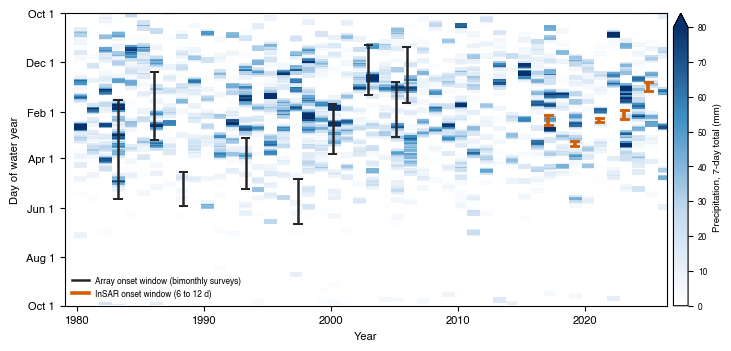

In [8]:
# [16]
def onset_bar(ax, x, day_lo, day_hi, color, lw):
    """A vertical bar from day_lo to day_hi of the water year at x, wrapping across Oct 1 if needed."""
    if day_hi >= day_lo:
        segments = [(day_lo, day_hi)]
    else:
        segments = [(day_lo, 366), (1, day_hi)]
    for segment_lo, segment_hi in segments:
        ax.plot([x, x], [segment_lo, segment_hi], "-", color=color, lw=lw, solid_capstyle="butt", zorder=5)
    for y in (day_lo, day_hi):
        ax.plot([x - 0.28, x + 0.28], [y, y], "-", color=color, lw=lw * 0.8, zorder=5)


insar_window_days = (insar_events.onset_hi - insar_events.onset_lo) * 365.25
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
fig, ax = plt.subplots(figsize=(7.2, 3.4), constrained_layout=True)
rain_plot = rain[(rain.wy >= int(np.floor(x0)) + 1) & (rain.wy <= int(np.ceil(x1)))]
rain_7d = rain_plot.prcp_mm.fillna(0).rolling(density_days, min_periods=1).sum()
water_years = sorted(rain_plot.wy.unique())
rain_grid = np.full((367, len(water_years)), np.nan)          # day of water year x water year
x_edges = []
for j, wy in enumerate(water_years):
    this_year = rain_plot[rain_plot.wy == wy]
    rain_grid[this_year.dowy.values, j] = rain_7d[this_year.index].values
    x_edges.append(wy - 1 + 273 / 365.25)
x_edges.append(water_years[-1] + 273 / 365.25)
cmap = LinearSegmentedColormap.from_list("rain", rain_colours)
mesh = ax.pcolormesh(np.array(x_edges), np.arange(-0.5, 367.5), rain_grid, cmap=cmap, vmin=0, vmax=density_max, shading="flat", rasterized=True, zorder=0)
for src, bar_colour, bar_width in (("aa_dense", array_bar_colour, 1.8), ("insar", insar_bar_colour, 2.6)):
    for event in onset_days[onset_days.src == src].itertuples():        # the local days (the day convention)
        onset_bar(ax, event.onset_mid, dowy([event.day_lo])[0], dowy([event.day_hi])[0], bar_colour, bar_width)
ax.set_xlim(x0, x1)
ax.set_ylim(366, 1)
ax.set_yticks([1, 62, 124, 182, 244, 305, 366])
ax.set_yticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_xlabel("Year")
ax.set_ylabel("Day of water year")
cb = fig.colorbar(mesh, ax=ax, pad=0.01, fraction=0.03, extend="max")
cb.set_label(f"Precipitation, {density_days}-day total (mm)", fontsize=7)
cb.ax.tick_params(labelsize=6)
ax.legend(handles=[Line2D([], [], color=array_bar_colour, lw=1.8, label="Array onset window (bimonthly surveys)"),
                   Line2D([], [], color=insar_bar_colour, lw=2.6,
                          label=f"InSAR onset window ({insar_window_days.min():.0f} to {insar_window_days.max():.0f} d)")],
          fontsize=6, loc="lower left")
f_season = os.path.join(fig_dir, f"qc10_onset_seasonality_wateryear_density{density_days}d_vmax{density_max}mm.png")
fig.savefig(f_season, dpi=300)
fig.savefig(f_season.replace(".png", ".pdf"))
print("Saved figure to:", f_season)
plt.show()

## [17] Rainfall conditioning of the onset timing: rules A and B (moved from 11_forecast, 2026-10-06)

Every quantity is a range over the onset window (the event is equally likely
anywhere in it), the window in local calendar days (`onset_days`, [12]). Rule A: lag after the water-year cumulative first exceeds
Y mm. Rule B: lag after the first 3-day storm of at least Z mm. Both rules use
the composite rain of [8] (Fremont, then Newark) and are scored on the InSAR onsets,
with the array onsets as a consistency count. The calendar spread of the InSAR
onsets is the baseline any rule has to beat. The test of a 3-day rain total
before the onset, on the InSAR onsets and the Fremont gauge only, is the next
cell pair ([19], [20]). The water years drawn run from the first complete one (`complete_wy`) to the
last in the rain series; the WY-total percentiles are over every water year of `complete_wy` in the
composite, as 11 computed them until 2026-10-06 (WY1984, 25 days missing, included).

In [9]:
# [18]
n_insar_events = len(insar_events)
n_aa_events = len(aa_dense)
wy_years = (complete_wy[0], int(rain.wy.max()))              # the water years drawn: the first complete one to the last in the series


def wy_series(wy):
    """One water year of the daily rain with its cumulative total and running rain_total_days-day storm total."""
    this_year = rain[rain.wy == wy].copy()
    this_year["cum"] = this_year.prcp_mm.fillna(0).cumsum()
    this_year["storm"] = this_year.prcp_mm.fillna(0).rolling(rain_total_days, min_periods=1).sum()
    return this_year


def first_date(this_year, column, threshold):
    """The first day of the water year on which `column` reaches `threshold` (NaT if never)."""
    hits = this_year.index[this_year[column] >= threshold]
    return hits[0] if len(hits) else pd.NaT


def lag_days(day, crossing):
    """Days from a threshold crossing to a day (NaN if the threshold was never reached)."""
    if pd.isna(crossing):
        return np.nan
    return (day - crossing).days


# antecedent rain at every day: 30-day total, largest storm in 30 days, days since the last >= antecedent_storm_mm storm
rain_daily = rain.prcp_mm.fillna(0)
storm_3d = rain_daily.rolling(rain_total_days, min_periods=1).sum()
antecedent = pd.DataFrame(index=rain.index)
antecedent["rain_30d"] = rain_daily.rolling(30, min_periods=1).sum()
antecedent["max_storm_30d"] = storm_3d.rolling(30, min_periods=1).max()
last_storm_day = pd.Series(np.where(storm_3d >= antecedent_storm_mm, np.arange(len(rain)), np.nan), index=rain.index).ffill()
antecedent["days_since_storm20"] = np.arange(len(rain)) - last_storm_day

# per event (array bimonthly era + InSAR): the rain state over its onset window (local days, onset_days), and the lags
# after each rule A / rule B threshold
events = onset_days[["src", "onset_lo", "onset_hi", "day_lo", "day_hi"]].copy()
events["source"] = np.where(events.src == "aa_dense", "AA", "InSAR")     # the labels of precip_conditioning_events.csv
events = events.sort_values("onset_lo").reset_index(drop=True)
event_rows = []
for event in events.itertuples():
    date_lo, date_hi = event.day_lo, event.day_hi                      # local days (the day convention, [12])
    _, wy = dowy_of(date_hi)
    this_year = wy_series(wy)
    cum_at_lo = float(this_year.cum.asof(date_lo)) if date_lo >= this_year.index[0] else 0.0
    row = dict(source=event.source, onset_lo=date_lo.date(), onset_hi=date_hi.date(), window_days=(date_hi - date_lo).days, wy=wy,
               dowy_lo=dowy_of(date_lo)[0], dowy_hi=dowy_of(date_hi)[0], wy_total_mm=float(this_year.cum.iloc[-1]),
               cum_at_lo=cum_at_lo, cum_at_hi=float(this_year.cum.asof(date_hi)), gauge=this_year.src.mode().iloc[0])
    row["frac_at_hi"] = row["cum_at_hi"] / row["wy_total_mm"]
    window_antecedent = antecedent.loc[date_lo:date_hi]
    for column in ("rain_30d", "max_storm_30d", "days_since_storm20"):
        row[f"{column}_min"] = float(window_antecedent[column].min())
        row[f"{column}_max"] = float(window_antecedent[column].max())
    for Y in y_grid:
        crossing = first_date(this_year, "cum", Y)
        row[f"lagY{Y}_lo"] = lag_days(date_lo, crossing)
        row[f"lagY{Y}_hi"] = lag_days(date_hi, crossing)
    for Z in z_grid:
        crossing = first_date(this_year, "storm", Z)
        row[f"lagZ{Z}_lo"] = lag_days(date_lo, crossing)
        row[f"lagZ{Z}_hi"] = lag_days(date_hi, crossing)
    event_rows.append(row)
event_rain = pd.DataFrame(event_rows)
event_rain.to_csv(os.path.join(out_dir, "precip_conditioning_events.csv"), index=False, float_format="%.1f")
insar_rain = event_rain[event_rain.source == "InSAR"]
aa_rain = event_rain[event_rain.source == "AA"]
n_insar = len(insar_rain)
n_aa = len(aa_rain)
assert n_insar == n_insar_events and n_aa == n_aa_events


def rule_scores(kind, thresholds):
    """Rules A (kind 'Y', WY cumulative) and B (kind 'Z', first storm): for each threshold, the InSAR lag range,
    how many array events are consistent with it, and when the threshold is typically crossed."""
    scores = []
    for threshold in thresholds:
        lag_lo = insar_rain[f"lag{kind}{threshold}_lo"]
        lag_hi = insar_rain[f"lag{kind}{threshold}_hi"]
        if lag_lo.isna().any():
            scores.append(dict(kind=kind, thr=threshold, n_insar_reached=int(lag_lo.notna().sum())))
            continue
        insar_lag_min = int(lag_lo.min())
        insar_lag_max = int(lag_hi.max())
        aa_lag_lo = aa_rain[f"lag{kind}{threshold}_lo"]
        aa_lag_hi = aa_rain[f"lag{kind}{threshold}_hi"]
        reached = aa_lag_lo.notna()
        consistent = reached & (aa_lag_hi >= insar_lag_min) & (aa_lag_lo <= insar_lag_max)
        crossing_dowy = {}
        for wy in range(wy_years[0], wy_years[1] + 1):
            crossing = first_date(wy_series(wy), "cum" if kind == "Y" else "storm", threshold)
            crossing_dowy[wy] = dowy_of(crossing)[0] if pd.notna(crossing) else np.nan
        crossing_dowy = pd.Series(crossing_dowy)
        scores.append(dict(kind=kind, thr=threshold, n_insar_reached=n_insar, insar_lag_min=insar_lag_min, insar_lag_max=insar_lag_max,
                           insar_lag_spread=insar_lag_max - insar_lag_min, aa_reached=int(reached.sum()), aa_consistent=int(consistent.sum()),
                           wy_reached_frac=float(crossing_dowy.notna().mean()), cross_dowy_median=float(crossing_dowy.median()),
                           cross_dowy_10=float(crossing_dowy.quantile(.1)), cross_dowy_90=float(crossing_dowy.quantile(.9))))
    return pd.DataFrame(scores)


threshold_scores = pd.concat([rule_scores("Y", y_grid), rule_scores("Z", z_grid)])
threshold_scores.to_csv(os.path.join(out_dir, "precip_conditioning_thresholds.csv"), index=False, float_format="%.2f")

# the summary lines
calendar_spread = int(insar_rain.dowy_hi.max() - insar_rain.dowy_lo.min())
wy_total_series = rain.groupby("wy").prcp_mm.sum(min_count=1)
wy_total_series = wy_total_series[(wy_total_series.index >= complete_wy[0]) & (wy_total_series.index <= complete_wy[1])]
conditioning_lines = ["", "RAINFALL CONDITIONING (per event: WY rain accumulated by the window start..end; antecedent quantities are min-max over the window)"]
for event in event_rain.itertuples():
    conditioning_lines.append(
        f"  {event.source:<5} {event.onset_lo}..{event.onset_hi} ({event.window_days:3d} d) WY{event.wy} total {event.wy_total_mm:5.0f} mm "
        f"(P{(wy_total_series < event.wy_total_mm).mean() * 100:2.0f}) | cum {event.cum_at_lo:4.0f}-{event.cum_at_hi:4.0f} mm, frac {event.frac_at_hi:.2f} | "
        f"rain 30 d {event.rain_30d_min:3.0f}-{event.rain_30d_max:3.0f} mm, max {rain_total_days}-d storm {event.max_storm_30d_min:3.0f}-{event.max_storm_30d_max:3.0f} mm, "
        f"{event.days_since_storm20_min:3.0f}-{event.days_since_storm20_max:3.0f} d since >= {antecedent_storm_mm} mm storm [{event.gauge}]")
wy_percentiles = []
for value in insar_rain.wy_total_mm:
    wy_percentiles.append(f"P{(wy_total_series < value).mean() * 100:.0f}")
conditioning_lines += [
    f"InSAR events: WY totals {insar_rain.wy_total_mm.min():.0f}-{insar_rain.wy_total_mm.max():.0f} mm (" + ", ".join(wy_percentiles) + ")",
    f"InSAR onsets: day-of-WY {insar_rain.dowy_lo.min():.0f}-{insar_rain.dowy_hi.max():.0f} ({dowy_label(insar_rain.dowy_lo.min())}-{dowy_label(insar_rain.dowy_hi.max())}), "
    f"calendar spread {calendar_spread} d",
    f"InSAR onsets: WY rain accumulated by the onset {insar_rain.cum_at_lo.min():.0f}-{insar_rain.cum_at_hi.max():.0f} mm, "
    f"fraction of the WY total {insar_rain.frac_at_hi.min():.2f}-{insar_rain.frac_at_hi.max():.2f}",
    "rule A (lag after WY cumulative exceeds Y):"]
for score in threshold_scores[threshold_scores.kind == "Y"].itertuples():
    if score.n_insar_reached < n_insar:
        conditioning_lines.append(f"  Y={score.thr:4.0f} mm: reached in only {score.n_insar_reached}/{n_insar} InSAR event years -> no rule")
    else:
        conditioning_lines.append(f"  Y={score.thr:4.0f} mm: lag {score.insar_lag_min:4.0f}..{score.insar_lag_max:4.0f} d (spread {score.insar_lag_spread:3.0f} d) | "
                                  f"AA consistent {score.aa_consistent:.0f}/{score.aa_reached:.0f} | "
                                  f"reached in {score.wy_reached_frac * 100:3.0f}% of WYs, crossing {dowy_label(score.cross_dowy_median)}")
conditioning_lines.append(f"rule B (lag after the first {rain_total_days}-day storm >= Z):")
for score in threshold_scores[threshold_scores.kind == "Z"].itertuples():
    if score.n_insar_reached < n_insar:
        conditioning_lines.append(f"  Z={score.thr:4.0f} mm: reached in only {score.n_insar_reached}/{n_insar} InSAR event years -> no rule")
    else:
        conditioning_lines.append(f"  Z={score.thr:4.0f} mm: lag {score.insar_lag_min:4.0f}..{score.insar_lag_max:4.0f} d (spread {score.insar_lag_spread:3.0f} d) | "
                                  f"AA consistent {score.aa_consistent:.0f}/{score.aa_reached:.0f} | first storm {dowy_label(score.cross_dowy_median)}")
# the tightest rule of each kind
reached_all = threshold_scores[threshold_scores.n_insar_reached == n_insar]
best_rule_a = reached_all[reached_all.kind == "Y"].sort_values("insar_lag_spread").iloc[0]
best_rule_b = reached_all[reached_all.kind == "Z"].sort_values("insar_lag_spread").iloc[0]
conditioning_lines.append(
    f"tightest rules: A Y={best_rule_a.thr:.0f} mm lag {best_rule_a.insar_lag_min:.0f}..{best_rule_a.insar_lag_max:.0f} d "
    f"(spread {best_rule_a.insar_lag_spread:.0f} vs calendar {calendar_spread} d); "
    f"B Z={best_rule_b.thr:.0f} mm lag {best_rule_b.insar_lag_min:.0f}..{best_rule_b.insar_lag_max:.0f} d (spread {best_rule_b.insar_lag_spread:.0f} d)")
stats_lines += conditioning_lines
print("\n".join(conditioning_lines))


RAINFALL CONDITIONING (per event: WY rain accumulated by the window start..end; antecedent quantities are min-max over the window)
  AA    1983-01-17..1983-05-21 (124 d) WY1983 total   738 mm (P96) | cum  191- 710 mm, frac 0.96 | rain 30 d  28-218 mm, max 3-d storm  20- 71 mm,   0- 30 d since >= 20 mm storm [NEWARK]
  AA    1985-12-13..1986-03-08 ( 85 d) WY1986 total   444 mm (P74) | cum  115- 346 mm, frac 0.78 | rain 30 d  27-156 mm, max 3-d storm  20- 48 mm,   0- 29 d since >= 20 mm storm [NEWARK]
  AA    1988-04-16..1988-05-29 ( 43 d) WY1988 total   213 mm (P 9) | cum  180- 211 mm, frac 0.99 | rain 30 d   7- 32 mm, max 3-d storm   6- 13 mm,  89-132 d since >= 20 mm storm [NEWARK]
  AA    1993-03-06..1993-05-08 ( 63 d) WY1993 total   546 mm (P87) | cum  442- 524 mm, frac 0.96 | rain 30 d  14-121 mm, max 3-d storm  10- 58 mm,   0- 42 d since >= 20 mm storm [NEWARK]
  AA    1997-04-26..1997-06-21 ( 56 d) WY1997 total   408 mm (P61) | cum  382- 395 mm, frac 0.97 | rain 30 d   0- 13 mm,

## [19] A 3-day rain total before the InSAR onsets: the sweep, with its search paid for (moved from 11_forecast)

Does an InSAR onset follow heavy rain more often than a random day of the same season would?
A day counts as wet when its rain and that of the two days before it (`rain_total_days`) add up to
at least Z mm; an onset is a hit when it falls within X days after a wet day. Z and X were not
fixed in advance, so the test is the whole sweep: Z in `rain_total_grid_mm`, X in
`rain_lag_grid_d`, 16 settings, and the search over them is paid for.

Only the five InSAR onsets (their windows are one acquisition interval long) and only the
Fremont gauge: the other gauge of the composite is there to draw the rain back in time. A day
without a Fremont reading counts as 0 mm; [12] asserts that each InSAR window and the
`insar_rain_check_days` before it hold no other gauge's rain (and prints the days with no data).

Each onset is drawn `n_draws` times, uniformly over the local days of its window (`onset_days`), both ends included
(never the midpoint). The observed statistic is the number of hits out of five, averaged over the
draws. The null keeps each event in its OWN water year and moves its onset to a day of the water
year drawn from all the onset draws pooled (the season the onsets occur in), `n_null` times. For
each setting, p = the fraction of null realisations with at least the observed hits. The best
setting is the one with the smallest p; the search-paid p is the fraction of null realisations
whose own best p over the 16 settings is at least as small. A random-number generator of its own
(`rain_test_seed`, 7, the seed the test had in 11) makes the test reproduce exactly.

In [10]:
# [20]


def days_since(flag):
    """Days since the last True in a daily boolean Series (NaN before the first)."""
    day_number = pd.Series(np.arange(len(flag)), index=flag.index, dtype=float)
    return day_number - day_number.where(flag).ffill()


def count_hits(days_since_wet, days, lag_d):
    """Hits summed over the events, one count per column of `days` (events x realisations, row numbers of the
    rain table): a hit is a day within lag_d days after a wet day."""
    return np.sum(days_since_wet[days] <= lag_d, axis=0)


def fraction_at_least(null_hits, value):
    """The fraction of the null realisations with at least `value` hits."""
    return float(np.mean(null_hits >= value))


# the Fremont gauge alone; a day without a Fremont reading counts as 0 mm in the 3-day totals
rain_step_days = np.diff(rain.index.values).astype("timedelta64[D]").astype(int)
assert (rain_step_days == 1).all(), "the rain table is not one row per day"
fremont_mm = rain.prcp_mm.where(rain.src == "FREMONT")
rain_3d_total = fremont_mm.fillna(0.0).rolling(rain_total_days, min_periods=1).sum()
row_of_day = pd.Series(np.arange(len(rain)), index=rain.index)

# each InSAR window: its first and last day as rows of the rain table, its water year, and the Fremont-only check
window_first_row = []
window_last_row = []
window_wy_start_row = []
window_wy = []
for event in insar_days.itertuples():
    date_lo, date_hi = event.day_lo, event.day_hi                      # local days (onset_days, [12]; Fremont alone, asserted there)
    _, wy_lo = dowy_of(date_lo)
    _, wy_hi = dowy_of(date_hi)
    assert wy_lo == wy_hi, f"InSAR window {date_lo.date()} to {date_hi.date()} spans two water years"
    window_first_row.append(int(row_of_day[date_lo]))
    window_last_row.append(int(row_of_day[date_hi]))
    window_wy_start_row.append(int(row_of_day[pd.Timestamp(f"{wy_lo - 1}-10-01")]))
    window_wy.append(wy_lo)

# the onset draws: each event n_draws times, uniformly over the days of its window, both ends included
sweep_rng = np.random.default_rng(rain_test_seed)
draw_rows = np.empty((n_insar_events, n_draws), dtype=int)          # events x draws, rows of the rain table
for i in range(n_insar_events):
    draw_rows[i] = sweep_rng.integers(window_first_row[i], window_last_row[i] + 1, n_draws)
season_dowy = rain.dowy.values[draw_rows].ravel()                   # the season the onsets occur in: every onset draw, pooled

# the null: each event in its own water year, on a day of the water year drawn from the pooled onset draws
null_dowy = sweep_rng.choice(season_dowy, size=(n_insar_events, n_null))
null_rows = np.empty((n_insar_events, n_null), dtype=int)           # events x null realisations
for i in range(n_insar_events):
    null_rows[i] = window_wy_start_row[i] + null_dowy[i] - 1
    assert (rain.wy.values[null_rows[i]] == window_wy[i]).all(), f"a null day left water year {window_wy[i]}"

# the sweep: for each setting, the expected hits over the onset draws and the null hits
sweep_rows = []
null_hits_by_setting = []        # one array of n_null hit counts per setting, in the order of sweep_rows
for Z in rain_total_grid_mm:
    days_since_wet = days_since(rain_3d_total >= Z).values
    assert np.isfinite(days_since_wet[null_rows]).all(), f"no 3-day total of {Z} mm at Fremont before an InSAR season day"
    for X in rain_lag_grid_d:
        observed_hits = float(np.mean(count_hits(days_since_wet, draw_rows, X)))      # expected hits over the onset draws
        null_hits = count_hits(days_since_wet, null_rows, X)
        null_hits_by_setting.append(null_hits)
        sweep_rows.append(dict(Z_mm=Z, X_d=X, hits=observed_hits, hits_pct=100 * observed_hits / n_insar_events,
                               null_mean=float(null_hits.mean()), null_pct=100 * float(null_hits.mean()) / n_insar_events,
                               p=fraction_at_least(null_hits, observed_hits)))
rain_sweep = pd.DataFrame(sweep_rows)
n_settings = len(rain_sweep)
rain_sweep.to_csv(os.path.join(out_dir, "rain_total_sweep.csv"), index=False, float_format="%.4f")

# the best setting: the smallest p (the first in the sweep's order on a tie)
best_index = 0
for k in range(n_settings):
    if rain_sweep.p.iloc[k] < rain_sweep.p.iloc[best_index]:
        best_index = k
best_sweep = rain_sweep.iloc[best_index]

# the search paid for: each null realisation's own p in every setting (against the same null), its smallest over the
# settings, and how often that is at least as small as the observed best p
null_best_p = np.ones(n_null)
for k in range(n_settings):
    ordered = np.sort(null_hits_by_setting[k])
    p_each = (n_null - np.searchsorted(ordered, null_hits_by_setting[k], side="left")) / n_null      # = fraction of the null >= its own hits
    null_best_p = np.minimum(null_best_p, p_each)
p_search_paid = float(np.mean(null_best_p <= best_sweep.p))

# the summary lines and the 4 x 4 table of p (rows Z, columns X)
p_table = rain_sweep.pivot(index="Z_mm", columns="X_d", values="p")
sweep_lines = ["", f"A {rain_total_days}-DAY RAIN TOTAL BEFORE THE INSAR ONSETS (Fremont gauge only; {n_insar_events} InSAR onsets, each drawn "
               f"{n_draws} times uniformly in its window; null: own water year, a random day of the onset season, {n_null} realisations)"]
sweep_lines.append(f"  one gauge: every InSAR window and the {insar_rain_check_days} d before it on Fremont alone (asserted in [12]); "
                   f"days with no data, counted as 0 mm: " + (", ".join(no_data_days) if no_data_days else "none"))
for row in rain_sweep.itertuples():
    sweep_lines.append(f"  {rain_total_days}-day total >= {row.Z_mm:2d} mm within {row.X_d:2d} d before the onset: hits {row.hits:4.2f} of {n_insar_events} "
                       f"({row.hits_pct:3.0f} %) vs {row.null_mean:4.2f} ({row.null_pct:3.0f} %) for a random day in the same season; p = {row.p:.3f}")
sweep_lines.append(f"p of each setting (rows: Z, mm; columns: X, d):\n{p_table.to_string(float_format=lambda value: f'{value:.3f}')}")
sweep_lines.append(f"{rain_total_days}-day rain total >= Z mm within X d before the InSAR onset: best Z/X {best_sweep.Z_mm:.0f} mm / {best_sweep.X_d:.0f} d: "
                   f"hits {best_sweep.hits:.2f} of {n_insar_events} vs {best_sweep.null_mean:.2f} expected for a random day in the same season, "
                   f"p = {best_sweep.p:.3f}; p = {p_search_paid:.3f} once all {n_settings} settings are paid for")
stats_lines += sweep_lines
print("\n".join(sweep_lines))


A 3-DAY RAIN TOTAL BEFORE THE INSAR ONSETS (Fremont gauge only; 5 InSAR onsets, each drawn 2000 times uniformly in its window; null: own water year, a random day of the onset season, 20000 realisations)
  one gauge: every InSAR window and the 30 d before it on Fremont alone (asserted in [12]); days with no data, counted as 0 mm: 2023-01-25, 2024-12-21, 2024-12-29, 2024-12-30
  3-day total >= 20 mm within  7 d before the onset: hits 1.36 of 5 ( 27 %) vs 2.55 ( 51 %) for a random day in the same season; p = 0.845
  3-day total >= 20 mm within 14 d before the onset: hits 3.01 of 5 ( 60 %) vs 3.51 ( 70 %) for a random day in the same season; p = 0.520
  3-day total >= 20 mm within 21 d before the onset: hits 4.28 of 5 ( 86 %) vs 4.12 ( 82 %) for a random day in the same season; p = 0.353
  3-day total >= 20 mm within 30 d before the onset: hits 5.00 of 5 (100 %) vs 4.61 ( 92 %) for a random day in the same season; p = 0.656
  3-day total >= 30 mm within  7 d before the onset: hits 0.65 of

## [21] Cumulative rain of every water year, with the onsets (supplement; moved from 11_forecast)

Is it the accumulated rain? Every water year's cumulative rain (the composite of [8])
as a grey line, the InSAR event years in colour with the onset window
as a thick segment, the array event years in dark grey. If the onsets waited
for a fixed amount of rain the segments would sit on one horizontal line;
instead they span the shaded band, a factor of several in accumulated rain
(and in fraction of the year's total). Whether the InSAR onsets follow a short
spell of heavy rain instead is the 3-day rain-total test of [20]
(`10_rain_sweep_*`), quoted under the figure.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-06/figS_wy_cumulative_rain_onsets.png


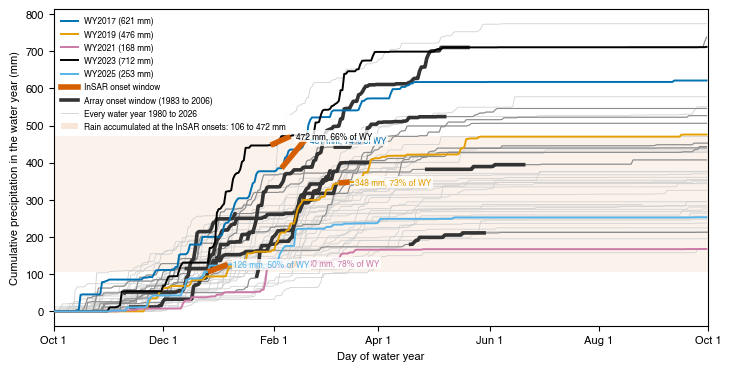

rain accumulated at the InSAR onsets: 106 to 472 mm, 50% to 78% of the water-year total; the 3-day rain-total test (Fremont): best 40 mm within 30 d, hits 5.00 of 5 vs 3.68 for a random day in the same season, p = 0.194, 0.501 with all 16 settings paid for


In [11]:
# [22]
insar_colour = insar_bar_colour         # Okabe-Ito vermillion: InSAR, as in every figure of 10 and 11
fig, ax = plt.subplots(figsize=(7.2, 3.6), constrained_layout=True)
# the band of accumulated rain at the InSAR onsets (window start to window end)
cum_lo = float(insar_rain.cum_at_lo.min())
cum_hi = float(insar_rain.cum_at_hi.max())
ax.axhspan(cum_lo, cum_hi, color=insar_colour, alpha=0.08, lw=0)
# every water year
for wy in range(wy_years[0], wy_years[1] + 1):
    this_year = wy_series(wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color="0.82", lw=0.6, zorder=1)
# the array event years (bimonthly era), onset window as a dark segment
for event in aa_rain.itertuples():
    this_year = wy_series(event.wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color="0.55", lw=0.8, zorder=2)
    segment = this_year[(this_year.dowy >= event.dowy_lo) & (this_year.dowy <= event.dowy_hi)]
    ax.plot(segment.dowy, segment.cum, "-", color="0.2", lw=2.6, solid_capstyle="butt", zorder=3)
# the InSAR event years in colour, onset window as a thick vermillion segment, labelled by water year
event_colours = ["#0072B2", "#E69F00", "#CC79A7", "#000000", "#56B4E9"]   # Okabe-Ito, no green (Dani)
assert len(event_colours) >= n_insar, "more InSAR events than distinct colours"
for colour, event in zip(event_colours, insar_rain.itertuples()):
    this_year = wy_series(event.wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color=colour, lw=1.4, zorder=4, label=f"WY{event.wy} ({event.wy_total_mm:.0f} mm)")
    ax.plot([event.dowy_lo, event.dowy_hi], [event.cum_at_lo, event.cum_at_hi], "-", color=insar_colour, lw=4, solid_capstyle="butt", zorder=5)
    ax.text(event.dowy_hi + 3, event.cum_at_hi, f"{event.cum_at_hi:.0f} mm, {event.frac_at_hi:.0%} of WY", fontsize=6, color=colour, va="center", zorder=6,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
ax.set_xlim(1, 366)
ax.set_xticks([1, 62, 124, 182, 244, 305, 366])
ax.set_xticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_ylabel("Cumulative precipitation in the water year (mm)")
ax.set_xlabel("Day of water year")
array_years_text = f"{int(np.floor(aa_dense.onset_lo.min()))} to {int(np.floor(aa_dense.onset_hi.max()))}"
legend_handles = ax.get_legend_handles_labels()[0]
legend_handles += [Line2D([], [], color=insar_colour, lw=4, label="InSAR onset window"),
                   Line2D([], [], color="0.2", lw=2.6, label=f"Array onset window ({array_years_text})"),
                   Line2D([], [], color="0.82", lw=0.6, label=f"Every water year {wy_years[0]} to {wy_years[1]}"),
                   plt.Rectangle((0, 0), 1, 1, facecolor=insar_colour, alpha=0.15, edgecolor="none",
                                 label=f"Rain accumulated at the InSAR onsets: {cum_lo:.0f} to {cum_hi:.0f} mm")]
ax.legend(handles=legend_handles, fontsize=6, loc="upper left")
f_cumulative = os.path.join(fig_dir, "figS_wy_cumulative_rain_onsets.png")
fig.savefig(f_cumulative, dpi=300)
fig.savefig(f_cumulative.replace(".png", ".pdf"))
print("Saved figure to:", f_cumulative)
plt.show()
print(f"rain accumulated at the InSAR onsets: {cum_lo:.0f} to {cum_hi:.0f} mm, {insar_rain.frac_at_hi.min():.0%} to {insar_rain.frac_at_hi.max():.0%} of the water-year total; "
      f"the 3-day rain-total test (Fremont): best {best_sweep.Z_mm:.0f} mm within {best_sweep.X_d:.0f} d, hits {best_sweep.hits:.2f} of {n_insar_events} "
      f"vs {best_sweep.null_mean:.2f} for a random day in the same season, p = {best_sweep.p:.3f}, {p_search_paid:.3f} with all {n_settings} settings paid for")

## [23] Supplementary figure: the rainfall conditioning (moved from 11_forecast)

WY accumulation with the onsets; the lag after each rule A threshold; onset
day against the day the best rule A threshold was crossed; and the p of every
setting of the 3-day rain-total test of [20] (rows Z, columns X, the best
setting outlined), with the search-paid p in the panel title.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-06/figS_precip_conditioning_bestY125mm_rain3d_sweep16_nnull20000.png


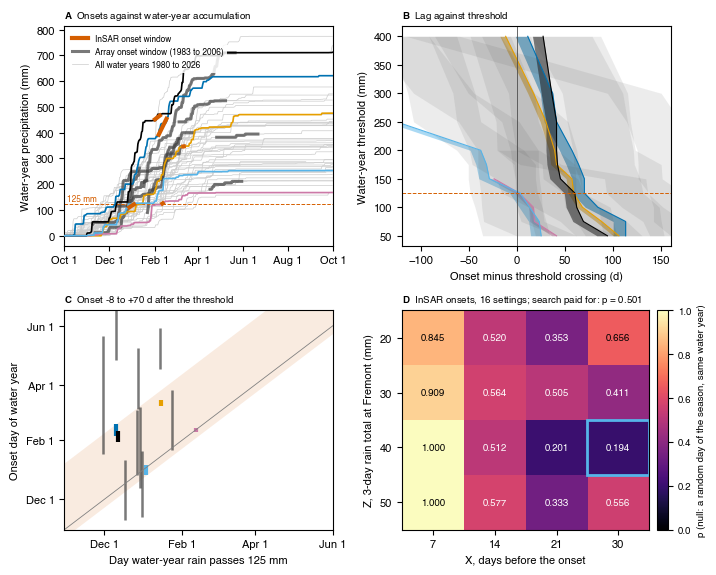

In [12]:
# [24]
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.8))
# a) every water year's accumulation, the InSAR event years in colour, the onset windows as thick segments
ax = axes[0, 0]
for wy in range(wy_years[0], wy_years[1] + 1):
    this_year = wy_series(wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color="0.8", lw=0.5, zorder=1)
for colour, event in zip(event_colours, insar_rain.itertuples()):
    this_year = wy_series(event.wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color=colour, lw=1.2, zorder=3, label=f"WY{event.wy}")
    ax.plot([event.dowy_lo, event.dowy_hi], [event.cum_at_lo, event.cum_at_hi], "-", color=insar_colour, lw=3, solid_capstyle="butt", zorder=4)
for event in aa_rain.itertuples():
    this_year = wy_series(event.wy)
    segment = this_year[(this_year.dowy >= event.dowy_lo) & (this_year.dowy <= event.dowy_hi)]
    ax.plot(segment.dowy, segment.cum, "-", color="0.25", lw=2.2, alpha=0.7, zorder=2)
ax.axhline(best_rule_a.thr, color=insar_colour, lw=0.7, ls="--")
ax.text(5, best_rule_a.thr + 8, f"{best_rule_a.thr:.0f} mm", fontsize=6, color=insar_colour)
ax.set_xlim(1, 366)
ax.set_xticks([1, 62, 124, 182, 244, 305, 366])
ax.set_xticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_ylabel("Water-year precipitation (mm)")
ax.legend(handles=[Line2D([], [], color=insar_colour, lw=3, label="InSAR onset window"),
                   Line2D([], [], color="0.25", lw=2.2, alpha=0.7, label=f"Array onset window ({array_years_text})"),
                   Line2D([], [], color="0.8", lw=0.5, label=f"All water years {wy_years[0]} to {wy_years[1]}")], fontsize=6, loc="upper left")
utils.panel_title(ax, "A", "Onsets against water-year accumulation")
# b) the lag of each onset after every rule A threshold
ax = axes[0, 1]
thresholds = list(threshold_scores[threshold_scores.kind == "Y"].thr)
for colour, event in zip(event_colours, insar_rain.itertuples()):
    lag_lo = []
    lag_hi = []
    for Y in thresholds:
        lag_lo.append(getattr(event, f"lagY{Y}_lo"))
        lag_hi.append(getattr(event, f"lagY{Y}_hi"))
    ax.fill_betweenx(thresholds, lag_lo, lag_hi, color=colour, alpha=0.5, lw=0)
    ax.plot(lag_hi, thresholds, "-", color=colour, lw=0.8)
for event in aa_rain.itertuples():
    lag_lo = []
    lag_hi = []
    for Y in thresholds:
        lag_lo.append(getattr(event, f"lagY{Y}_lo"))
        lag_hi.append(getattr(event, f"lagY{Y}_hi"))
    ax.fill_betweenx(thresholds, lag_lo, lag_hi, color="0.3", alpha=0.10, lw=0)
ax.axvline(0, color="0.3", lw=0.6)
ax.axhline(best_rule_a.thr, color=insar_colour, lw=0.7, ls="--")
ax.set_xlim(-120, 160)
ax.set_xlabel("Onset minus threshold crossing (d)")
ax.set_ylabel("Water-year threshold (mm)")
utils.panel_title(ax, "B", "Lag against threshold")
# c) onset day against the day the best rule A threshold was crossed
ax = axes[1, 0]
best_Y = int(best_rule_a.thr)
for colour, event in zip(event_colours, insar_rain.itertuples()):
    crossing_day = event.dowy_hi - getattr(event, f"lagY{best_Y}_hi")
    ax.plot([crossing_day, crossing_day], [event.dowy_lo, event.dowy_hi], "-", color=colour, lw=3, solid_capstyle="butt")
for event in aa_rain.itertuples():
    lag = getattr(event, f"lagY{best_Y}_hi")
    if np.isfinite(lag):
        crossing_day = event.dowy_hi - lag
        ax.plot([crossing_day, crossing_day], [event.dowy_lo, event.dowy_hi], "-", color="0.25", lw=1.8, alpha=0.7, solid_capstyle="butt")
diagonal = np.array([1, 366])
ax.plot(diagonal, diagonal, "-", color="0.5", lw=0.6)
ax.fill_between(diagonal, diagonal + best_rule_a.insar_lag_min, diagonal + best_rule_a.insar_lag_max, color=insar_colour, alpha=0.12, lw=0)
ax.set_xlim(30, 220)
ax.set_ylim(30, 260)
ticks = [62, 124, 182, 244]
tick_labels = ["Dec 1", "Feb 1", "Apr 1", "Jun 1"]
ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels)
ax.set_yticks(ticks)
ax.set_yticklabels(tick_labels)
ax.set_xlabel(f"Day water-year rain passes {best_Y} mm")
ax.set_ylabel("Onset day of water year")
utils.panel_title(ax, "C", f"Onset {best_rule_a.insar_lag_min:+.0f} to {best_rule_a.insar_lag_max:+.0f} d after the threshold")
# d) the 3-day rain-total test: p of every setting (rows Z, columns X), the number written in each cell, the best outlined
ax = axes[1, 1]
p_cmap = plt.get_cmap("magma")                       # sequential, no blue or green
image = ax.imshow(p_table.values, cmap=p_cmap, vmin=0, vmax=1, aspect="auto")
for i, Z in enumerate(p_table.index):
    for j, X in enumerate(p_table.columns):
        p_value = float(p_table.loc[Z, X])
        red, green, blue, _ = p_cmap(p_value)
        text_colour = "white" if 0.299 * red + 0.587 * green + 0.114 * blue < 0.5 else "black"     # readable on the cell's own colour
        ax.text(j, i, f"{p_value:.3f}", ha="center", va="center", fontsize=7, color=text_colour)
best_row = list(p_table.index).index(best_sweep.Z_mm)
best_column = list(p_table.columns).index(best_sweep.X_d)
ax.add_patch(plt.Rectangle((best_column - 0.5, best_row - 0.5), 1, 1, facecolor="none", edgecolor="#56B4E9", lw=2))   # Okabe-Ito sky blue
ax.set_xticks(range(len(p_table.columns)))
ax.set_xticklabels([f"{X}" for X in p_table.columns])
ax.set_yticks(range(len(p_table.index)))
ax.set_yticklabels([f"{Z}" for Z in p_table.index])
ax.set_xlabel("X, days before the onset")
ax.set_ylabel(f"Z, {rain_total_days}-day rain total at Fremont (mm)")
colour_bar = fig.colorbar(image, ax=ax, fraction=0.05, pad=0.03)
colour_bar.set_label("p (null: a random day of the season, same water year)", fontsize=7)
colour_bar.ax.tick_params(labelsize=7)
utils.panel_title(ax, "D", f"InSAR onsets, {n_settings} settings; search paid for: p = {p_search_paid:.3f}")
fig.tight_layout()
f_conditioning = os.path.join(fig_dir, f"figS_precip_conditioning_bestY{best_Y}mm_rain{rain_total_days}d_sweep{n_settings}_nnull{n_null}.png")
fig.savefig(f_conditioning, dpi=300)
fig.savefig(f_conditioning.replace(".png", ".pdf"))
print("Saved figure to:", f_conditioning)
plt.show()

## [25] The summary 11 reads: `rain_conditioning_summary.csv`

Part (3) of 11's prediction statement and its data line quote the rainfall conditioning. They
are written here, one row per scalar (name, value, unit, what it is), and 11 reads them (and
fingerprints the file) instead of recomputing anything: the onset days on the water year, the
rain accumulated at the onsets, the WY-total percentiles, the rain-total test (best setting,
its p and the search-paid p), the spreads of the tightest rules against the calendar spread, and
the last day with a Fremont reading.

In [13]:
# [26]
fremont_last_day = rain.index[(rain.src == "FREMONT") & rain.prcp_mm.notna()].max()
summary_rows = [
    ("n_insar_onsets", n_insar, "count", "InSAR onset windows"),
    ("onset_dowy_min", int(insar_rain.dowy_lo.min()), "d", "first day of water year of any InSAR onset window"),
    ("onset_dowy_max", int(insar_rain.dowy_hi.max()), "d", "last day of water year of any InSAR onset window"),
    ("onset_earliest", dowy_label(insar_rain.dowy_lo.min()), "date", "onset_dowy_min as 'Mon DD'"),
    ("onset_latest", dowy_label(insar_rain.dowy_hi.max()), "date", "onset_dowy_max as 'Mon DD'"),
    ("calendar_spread_d", calendar_spread, "d", "onset_dowy_max - onset_dowy_min"),
    ("cum_at_onset_min_mm", float(insar_rain.cum_at_lo.min()), "mm", "WY rain accumulated by the earliest window start"),
    ("cum_at_onset_max_mm", float(insar_rain.cum_at_hi.max()), "mm", "WY rain accumulated by the latest window end"),
    ("frac_at_onset_min", float(insar_rain.frac_at_hi.min()), "1", "fraction of the WY total by the window end, min"),
    ("frac_at_onset_max", float(insar_rain.frac_at_hi.max()), "1", "fraction of the WY total by the window end, max"),
    ("wy_percentile_min", float((wy_total_series < insar_rain.wy_total_mm.min()).mean() * 100), "pct", "percentile of the driest InSAR event year"),
    ("wy_percentile_max", float((wy_total_series < insar_rain.wy_total_mm.max()).mean() * 100), "pct", "percentile of the wettest InSAR event year"),
    ("wy_first", complete_wy[0], "wy", "first water year of the WY-total distribution"),
    ("wy_last", complete_wy[1], "wy", "last water year of the WY-total distribution"),
    ("rain_total_days", rain_total_days, "d", "length of the running rain total"),
    ("rain_sweep_best_Z_mm", float(best_sweep.Z_mm), "mm", "best setting: 3-day total of at least Z mm"),
    ("rain_sweep_best_X_d", float(best_sweep.X_d), "d", "best setting: within X days before the onset"),
    ("rain_sweep_best_hits", float(best_sweep.hits), "count", "best setting: expected hits over the onset draws"),
    ("rain_sweep_best_null_hits", float(best_sweep.null_mean), "count", "best setting: hits of a random day of the same season"),
    ("rain_sweep_best_p", float(best_sweep.p), "1", "best setting's own p"),
    ("rain_sweep_p_search_paid", p_search_paid, "1", "p once all settings are paid for (the number to quote)"),
    ("rain_sweep_n_settings", n_settings, "count", "settings of Z and X swept"),
    ("ruleA_best_spread_d", float(best_rule_a.insar_lag_spread), "d", "tightest rule A: spread of the InSAR lags"),
    ("ruleB_best_spread_d", float(best_rule_b.insar_lag_spread), "d", "tightest rule B: spread of the InSAR lags"),
    ("fremont_last_valid_day", str(fremont_last_day.date()), "date", "last day with a Fremont reading in the rain series"),
]
rain_summary = pd.DataFrame(summary_rows, columns=["name", "value", "unit", "description"])
assert rain_summary.name.is_unique
rain_summary.to_csv(os.path.join(out_dir, "rain_conditioning_summary.csv"), index=False)
print(rain_summary.to_string(index=False))
print("saved rain_conditioning_summary.csv for 11_forecast")

                     name      value  unit                                            description
           n_insar_onsets          5 count                                    InSAR onset windows
           onset_dowy_min         87     d      first day of water year of any InSAR onset window
           onset_dowy_max        166     d       last day of water year of any InSAR onset window
           onset_earliest     Dec 26  date                             onset_dowy_min as 'Mon DD'
             onset_latest     Mar 15  date                             onset_dowy_max as 'Mon DD'
        calendar_spread_d         79     d                        onset_dowy_max - onset_dowy_min
      cum_at_onset_min_mm      106.1    mm       WY rain accumulated by the earliest window start
      cum_at_onset_max_mm      471.5    mm           WY rain accumulated by the latest window end
        frac_at_onset_min   0.498617     1        fraction of the WY total by the window end, min
        frac_at_onse

## [27] The Fig 3 panels: the HRKT history and the onsets on the water year

Fig 3 is drawn by 11_forecast, which also has the repeat intervals and the forecast. This cell saves
what its left column needs: the rain grid on the water year, the onset windows of both catalogues (day
of water year of each window end), and the end of the bimonthly HRKT surveys.

In [14]:
# [28]
hrkt = utils.load_aa(common_paths["aa_dir"], "HRKT")
hrkt_stack = pd.read_csv(stacks_file).query("code == 'HRKT'")
# the bimonthly surveys end at the last HRKT survey that closes an interval of resolvable_days or less (as 09's
# bimonthly_era); the arrays were then surveyed annually until InSAR
survey_gap_days = np.diff(hrkt.year.values) * 365.25
dense_era_end = float(hrkt.year.values[np.max(np.where(survey_gap_days <= resolvable_days)[0]) + 1])
insar_start = float(hrkt_stack.date.min())
print(f"bimonthly surveys at HRKT end {dense_era_end:.2f}; annual surveys from then until the InSAR record starts {insar_start:.2f}")
# the windows as local days (onset_days, the day convention); 11 reads day_lo/day_hi for every rain quantity
windows = onset_days[["src", "onset_lo", "onset_hi", "onset_mid", "day_lo", "day_hi", "utc_lo", "utc_hi", "window_day_basis"]].copy()
windows["dowy_lo"] = np.asarray(dowy(windows.day_lo))
windows["dowy_hi"] = np.asarray(dowy(windows.day_hi))
windows["day_lo"] = windows.day_lo.dt.strftime("%Y-%m-%d")
windows["day_hi"] = windows.day_hi.dt.strftime("%Y-%m-%d")
assert len(windows) == len(aa_dense) + len(insar_events) and windows[["dowy_lo", "dowy_hi"]].notna().all().all()
windows.to_csv(os.path.join(out_dir, "fig3_onset_windows.csv"), index=False)
np.savez(os.path.join(out_dir, "fig3_rain_panel.npz"), rain_grid=rain_grid, x_edges=np.asarray(x_edges), density_days=density_days,
         density_max=density_max, x0=x0, x1=x1, loma_prieta=loma_prieta, dense_era_end=dense_era_end, insar_start=insar_start,
         rain_colours=np.array(rain_colours), wet_season_months=np.array(wet_season_months))     # 11 checks it uses the same season
print("saved fig3_onset_windows.csv and fig3_rain_panel.npz for 11_forecast")

bimonthly surveys at HRKT end 2007.44; annual surveys from then until the InSAR record starts 2016.67
saved fig3_onset_windows.csv and fig3_rain_panel.npz for 11_forecast


## [29] Registry: the stats sidecar `10_rain_stats.txt` and the `10_*` numbers

In [15]:
# [30]
stats_lines += ["", f"onset windows against the wet season ({wet_season_text}, months {wet_season_months}, {wet_season_source}; "
                f"{100 * wet_share.median():.0f} % of the year's rain): "
                f"{n_wet_inside} of {len(event_table)} wholly inside, {n_wet_partly} partly, {n_wet_outside} wholly outside; "
                f"InSAR {n_insar_wet_inside} of {is_insar.sum()} wholly inside"]
sidecar = REG.sidecar("10_rain", stats_lines)
REG.register("10_rain_series_start", str(days[0].date()), "date", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("10_rain_series_end", str(days[-1].date()), "date", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("10_wy_median_mm", complete_years.total_mm.median(), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("10_wy_p10_mm", complete_years.total_mm.quantile(.1), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("10_wy_p90_mm", complete_years.total_mm.quantile(.9), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("10_n_aa_season_resolved", len(aa_dense), "count", 0, where="Fig3 caption", cell="catalogues", sidecar=sidecar)
REG.register("10_n_events", len(event_table), "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
# the season is in the key (e.g. 10_n_wet_oct_apr_inside): a change of season retires the old keys instead of overwriting
# them (the November-to-March keys 10_n_wet_season_* and 10_wet_season_rain_pct were retired so on 2026-10-05)
REG.register(f"10_n_wet_{wet_season_tag}_inside", n_wet_inside, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register(f"10_n_wet_{wet_season_tag}_partly", n_wet_partly, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register(f"10_n_wet_{wet_season_tag}_outside", n_wet_outside, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register(f"10_n_insar_wet_{wet_season_tag}_inside", n_insar_wet_inside, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register(f"10_wet_{wet_season_tag}_rain_pct", 100 * wet_share.median(), "%", 0, where="P10", cell="seasonality", sidecar=sidecar)
# the rainfall conditioning ([18], [20]; 11_forecast's 11_onset_*, 11_wy_*, 11_cum_at_*, 11_frac_at_*, 11_ruleA/B_*,
# 11_rain_sweep_* until 2026-10-06, same values)
REG.register("10_insar_onset_dowy_min", int(insar_rain.dowy_lo.min()), "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_onset_dowy_max", int(insar_rain.dowy_hi.max()), "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_onset_earliest", dowy_label(insar_rain.dowy_lo.min()), "date", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_onset_latest", dowy_label(insar_rain.dowy_hi.max()), "date", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_onset_calendar_spread_d", calendar_spread, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_wy_total_min_mm", insar_rain.wy_total_mm.min(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_wy_total_max_mm", insar_rain.wy_total_mm.max(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_wy_percentile_min", (wy_total_series < insar_rain.wy_total_mm.min()).mean() * 100, "pct", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_wy_percentile_max", (wy_total_series < insar_rain.wy_total_mm.max()).mean() * 100, "pct", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_cum_at_onset_min_mm", insar_rain.cum_at_lo.min(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_cum_at_onset_max_mm", insar_rain.cum_at_hi.max(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_frac_at_onset_min", insar_rain.frac_at_hi.min(), "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_insar_frac_at_onset_max", insar_rain.frac_at_hi.max(), "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleA_best_Y_mm", best_rule_a.thr, "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleA_lag_min_d", best_rule_a.insar_lag_min, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleA_lag_max_d", best_rule_a.insar_lag_max, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleB_best_Z_mm", best_rule_b.thr, "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleB_lag_min_d", best_rule_b.insar_lag_min, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_ruleB_lag_max_d", best_rule_b.insar_lag_max, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("10_rain_sweep_best_Z_mm", int(best_sweep.Z_mm), "mm", 0, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("10_rain_sweep_best_X_d", int(best_sweep.X_d), "d", 0, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("10_rain_sweep_best_hits", best_sweep.hits, "count", 2, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("10_rain_sweep_best_null_hits", best_sweep.null_mean, "count", 2, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("10_rain_sweep_best_p", best_sweep.p, "1", 3, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("10_rain_sweep_p_search_paid", p_search_paid, "1", 3, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("10_rain_sweep_n_settings", n_settings, "count", 0, where="P10", cell="rain sweep", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/10_rain_seasonality/10_rain_stats.txt


  registered 10_rain_series_start = 1978-10-01 date  -> M9
  registered 10_rain_series_end = 2026-08-25 date  -> M9


  registered 10_wy_median_mm = 362 mm  -> M9


  registered 10_wy_p10_mm = 219 mm  -> M9


  registered 10_wy_p90_mm = 567 mm  -> M9


  registered 10_n_aa_season_resolved = 9 count  -> Fig3 caption


... (19 outputs left out)

  registered 10_rain_sweep_best_null_hits = 3.68 count  -> P10
  registered 10_rain_sweep_best_p = 0.194 1  -> P10
  registered 10_rain_sweep_p_search_paid = 0.501 1  -> P10


  registered 10_rain_sweep_n_settings = 16 count  -> P10


  01_prep_inputs: its latest run registered no numbers (sidecar newer than its last registry row); its keys are retired
  07b_uniform_model_tests: retired from the paper (TulePond_filepaths.retired_notebooks); its 26 keys are listed as RETIRED
Rendered registry to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt'